# 02 · Exploración y selección de features: Predict Future Sales

**Objetivo:** decidir, con datos, qué lags y qué operaciones de ingeniería de características usará el pipeline del notebook 03. Aquí todavía **no se crean operadores**: cada operación se prueba por separado sobre una muestra, y al final se lista por escrito qué se aplicará a cada variable.

**Punto de partida (EDA, notebook 01):**

- se trabaja a nivel **mensual** por par tienda-producto, con una **malla** que rellena con 0 los meses sin venta;
- la limpieza del EDA (duplicados, valores inválidos, tiendas unificadas) está en `future_sales.dataset`;
- las ventas pasadas del par son la variable más relacionada con el target, y la PACF mensual sugiere un AR(1) con un posible efecto en el rezago 12.

**Decisiones de la fase (usuario):**

| Tema | Decisión |
|---|---|
| Target | `item_cnt_month` recortado a [0, 20], como en Kaggle; métrica RMSE |
| Ventana | Entrenamiento con los meses 12-26 (para que exista el lag 12) y validación con los meses 27-33, en orden temporal |
| Lags | Se construyen con un operador propio dentro del pipeline (notebook 03), solo con meses anteriores al que se predice |

**Contenido**

1. Datos mensuales y malla
2. Selección de lags del par tienda-producto
3. Lags agregados (producto, tienda, categoría) y otras variables derivadas
4. Selección con un modelo de referencia
5. Procesos de ingeniería de características (imputación, codificación, outliers, transformación, escalado)
6. Resumen: variables, transformaciones y mapeos

## Configuración

Librerías, semilla y ventanas temporales. Toda la selección se hace con los meses de **entrenamiento** (12 a 26); los meses de validación (27 a 33) no se miran, para no contaminar la evaluación del notebook 04.

In [1]:
import time

from IPython.display import display
from feature_engine.encoding import MeanEncoder, OneHotEncoder, RareLabelEncoder
from feature_engine.imputation import (
    AddMissingIndicator,
    ArbitraryNumberImputer,
    CategoricalImputer,
    MeanMedianImputer,
)
from feature_engine.outliers import ArbitraryOutlierCapper, Winsorizer
from feature_engine.transformation import LogCpTransformer
from feature_engine.wrappers import SklearnTransformerWrapper
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from future_sales import dataset as ds

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["axes.titleweight"] = "bold"
COLOR = "#2a6f97"

SEMILLA = 42
MESES_MALLA = range(12, 34)
MESES_ENTRENAMIENTO = range(12, 27)
MESES_VALIDACION = range(27, 34)
LAGS_CANDIDATOS = range(1, 13)

2026-11-20 08:57:50.156 | INFO     | future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Proyecto\future-sales


## 1. Datos mensuales y malla

1. Se cargan las ventas y se aplica la limpieza decidida en el EDA (`ds.limpiar_ventas`).
2. Se agregan por mes, tienda y producto (`ds.ventas_mensuales`): `item_cnt_month` neto (con devoluciones) y precio medio.
3. Se arma la **malla** de los meses 12 a 33 (`ds.construir_malla`): para cada mes, todas las tiendas activas por todos los productos vendidos ese mes, con 0 donde no hubo venta. Es la misma estructura que `test.csv` (42 tiendas × 5,100 productos). El target se recorta a [0, 20].

In [2]:
inicio = time.time()
catalogos = ds.cargar_catalogos()
ventas = ds.limpiar_ventas(ds.cargar_ventas())
mensual = ds.ventas_mensuales(ventas, catalogos["items"])
malla = ds.construir_malla(mensual, MESES_MALLA)
print(f"Ventas diarias limpias: {len(ventas):,}")
print(f"Pares tienda-producto-mes con venta: {len(mensual):,}")
print(f"Filas de la malla (meses 12-33): {len(malla):,} "
      f"en {time.time() - inicio:.1f} s")

por_mes = malla.groupby("date_block_num").agg(
    filas=("item_cnt_month", "size"),
    tiendas=("shop_id", "nunique"),
    productos=("item_id", "nunique"),
    pct_ceros=("item_cnt_month", lambda s: (s == 0).mean() * 100),
    media_target=("item_cnt_month", "mean"),
)
display(por_mes.T)

Ventas diarias limpias: 2,935,840
Pares tienda-producto-mes con venta: 1,609,123
Filas de la malla (meses 12-33): 6,425,094 en 1.7 s


date_block_num,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33
filas,"347,346.000","328,164.000","342,816.000","331,926.000","327,565.000","327,369.000","330,550.000","324,513.000","303,550.000","329,368.000","316,100.000","330,250.000","306,950.000","284,491.000","279,772.000","257,372.000","232,452.000","224,288.000","228,889.000","214,536.000","218,655.000","238,172.000"
tiendas,46.000,46.000,48.000,49.000,49.000,49.000,50.000,51.000,50.000,52.000,50.000,50.000,50.000,47.000,46.000,47.000,44.000,43.000,43.000,42.000,43.000,44.000
productos,"7,551.000","7,134.000","7,142.000","6,774.000","6,685.000","6,681.000","6,611.000","6,363.000","6,071.000","6,334.000","6,322.000","6,605.000","6,139.000","6,053.000","6,082.000","5,476.000","5,283.000","5,216.000","5,323.000","5,108.000","5,085.000","5,413.000"
pct_ceros,84.694,85.504,85.649,86.546,86.053,85.833,86.189,85.717,86.718,87.095,85.557,82.081,84.812,85.488,85.577,87.250,86.167,85.800,85.382,84.419,86.461,86.786
media_target,0.311,0.307,0.300,0.256,0.269,0.273,0.255,0.291,0.272,0.280,0.311,0.444,0.317,0.278,0.274,0.243,0.260,0.264,0.259,0.288,0.264,0.259


### 1.1 Target recortado

Distribución de `item_cnt_month` en la malla, ya recortado a [0, 20].

Ceros: 85.6% | en el tope 20: 0.11% | media: 0.296 | desv.: 1.218


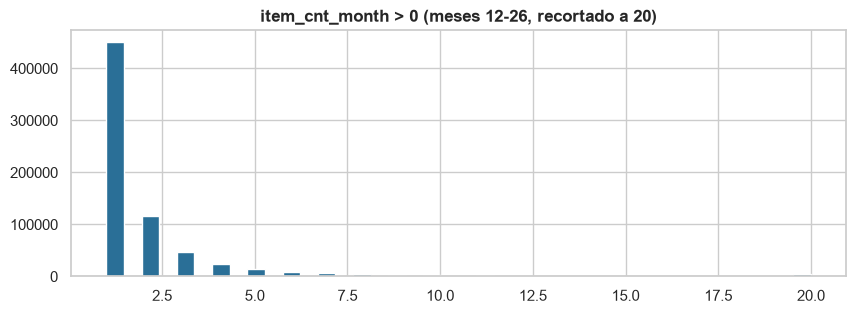

In [3]:
entrenamiento = malla["date_block_num"].isin(MESES_ENTRENAMIENTO)
y_ent = malla.loc[entrenamiento, "item_cnt_month"]
print(f"Ceros: {(y_ent == 0).mean():.1%} | en el tope 20: "
      f"{(y_ent == 20).mean():.2%} | media: {y_ent.mean():.3f} | "
      f"desv.: {y_ent.std():.3f}")
fig, eje = plt.subplots(figsize=(10, 3.2))
eje.hist(y_ent[y_ent > 0], bins=40, color=COLOR)
eje.set_title("item_cnt_month > 0 (meses 12-26, recortado a 20)")
plt.show()

## 2. Selección de lags del par tienda-producto

Para cada fila del mes `m`, el lag `k` es la venta del mismo par en el mes `m - k`. **Solo se usan meses anteriores**: para el mes 34 de test, los lags salen de los meses 33, 32, 31, etc. Como la malla empieza en el mes 12, los lags de 1 a 12 siempre caen dentro del historial (mes 0 en adelante): si el par no vendió en ese mes, el lag vale 0.

La función `agregar_lag` desplaza una tabla mensual `k` meses hacia adelante y la une a la malla.

In [4]:
def agregar_lag(df: pd.DataFrame, tabla: pd.DataFrame, llaves: list[str],
                k: int, nombre: str) -> pd.DataFrame:
    """Une el valor de `tabla` del mes m - k a cada fila del mes m."""
    previo = (tabla.assign(date_block_num=tabla["date_block_num"] + k)
              .rename(columns={"valor": nombre}))
    df = df.merge(previo[["date_block_num"] + llaves + [nombre]],
                  on=["date_block_num"] + llaves, how="left")
    df[nombre] = df[nombre].fillna(0).astype("float32")
    return df


tabla_par = mensual[["date_block_num", "shop_id", "item_id",
                     "item_cnt_month"]].rename(
    columns={"item_cnt_month": "valor"})
base = malla.copy()
for k in LAGS_CANDIDATOS:
    base = agregar_lag(base, tabla_par, ["shop_id", "item_id"], k,
                       f"ventas_par_lag_{k}")

# Verificación de fuga: el lag k de una fila del mes m es la venta del
# mes m - k (un mes anterior), nunca la del propio mes.
fila = base[(base["date_block_num"] == 20)
            & (base["ventas_par_lag_1"] > 0)].iloc[0]
venta_mes_anterior = tabla_par.query(
    "date_block_num == 19 and shop_id == @fila.shop_id "
    "and item_id == @fila.item_id")["valor"].sum()
assert fila["ventas_par_lag_1"] == venta_mes_anterior
print("Ejemplo (mes 20):", fila[["shop_id", "item_id", "item_cnt_month",
                                 "ventas_par_lag_1",
                                 "ventas_par_lag_2"]].to_dict())

Ejemplo (mes 20): {'shop_id': 2.0, 'item_id': 485.0, 'item_cnt_month': 1.0, 'ventas_par_lag_1': 1.0, 'ventas_par_lag_2': 0.0}


### 2.1 Correlación de cada lag con el target

Correlación de Pearson entre `item_cnt_month` y cada lag, en los meses de entrenamiento. Como el target está recortado, los lags también se evalúan recortados a 20 (esa es la versión que verá el modelo después del tratamiento de outliers).

,ventas_par_lag_1,ventas_par_lag_2,ventas_par_lag_3,ventas_par_lag_4,ventas_par_lag_5,ventas_par_lag_6,ventas_par_lag_7,ventas_par_lag_8,ventas_par_lag_9,ventas_par_lag_10,ventas_par_lag_11,ventas_par_lag_12
r_con_target,0.592,0.464,0.397,0.351,0.322,0.297,0.275,0.259,0.244,0.230,0.216,0.211
pct_filas_no_cero,14.216,14.057,13.769,13.246,13.016,12.811,12.534,12.080,11.634,11.333,10.958,10.628


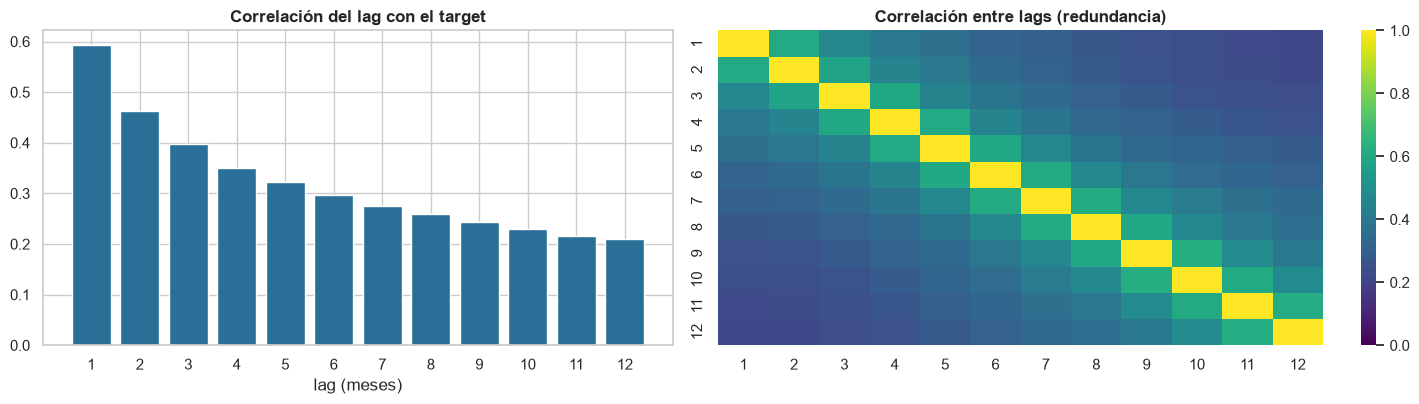

In [5]:
columnas_lag = [f"ventas_par_lag_{k}" for k in LAGS_CANDIDATOS]
base_ent = base[base["date_block_num"].isin(MESES_ENTRENAMIENTO)]
lags_recortados = base_ent[columnas_lag].clip(0, 20)
correlacion_lags = lags_recortados.corrwith(
    base_ent["item_cnt_month"]).rename("r_con_target").to_frame()
correlacion_lags["pct_filas_no_cero"] = (
    (base_ent[columnas_lag] != 0).mean() * 100)
display(correlacion_lags.T)

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.2),
                         gridspec_kw={"width_ratios": [1, 1.2]})
ejes[0].bar(list(LAGS_CANDIDATOS), correlacion_lags["r_con_target"],
            color=COLOR)
ejes[0].set_xticks(list(LAGS_CANDIDATOS))
ejes[0].set_xlabel("lag (meses)")
ejes[0].set_title("Correlación del lag con el target")
sns.heatmap(lags_recortados.sample(300_000, random_state=SEMILLA).corr(),
            cmap="viridis", vmin=0, vmax=1, ax=ejes[1],
            xticklabels=list(LAGS_CANDIDATOS),
            yticklabels=list(LAGS_CANDIDATOS))
ejes[1].set_title("Correlación entre lags (redundancia)")
plt.tight_layout()
plt.show()

### 2.2 Aporte incremental de cada lag

La correlación sola no dice si un lag agrega información que los anteriores no tengan. Se ajusta una regresión lineal agregando los lags de uno en uno y se mide el RMSE en los meses 25 y 26 (los dos últimos meses de entrenamiento), entrenando con los meses 12 a 24.

In [6]:
from sklearn.linear_model import LinearRegression

ajuste = base_ent["date_block_num"] <= 24
prueba = base_ent["date_block_num"] >= 25
y_ajuste = base_ent.loc[ajuste, "item_cnt_month"]
y_prueba = base_ent.loc[prueba, "item_cnt_month"]
filas = [{"lags": "ninguno (media)",
          "rmse": root_mean_squared_error(
              y_prueba, np.full(len(y_prueba), y_ajuste.mean()))}]
usados = []
for k in LAGS_CANDIDATOS:
    usados.append(f"ventas_par_lag_{k}")
    modelo = LinearRegression().fit(lags_recortados.loc[ajuste, usados],
                                    y_ajuste)
    prediccion = ds.recortar_target(
        modelo.predict(lags_recortados.loc[prueba, usados]))
    filas.append({"lags": f"1..{k}",
                  "rmse": root_mean_squared_error(y_prueba, prediccion)})
incremental = pd.DataFrame(filas)
incremental["mejora_vs_anterior"] = -incremental["rmse"].diff()
display(incremental)

,lags,rmse,mejora_vs_anterior
0,ninguno (media),1.081,NaN
1,1..1,0.870,0.212
2,1..2,0.860,0.010
3,1..3,0.858,0.001
4,1..4,0.854,0.005
5,1..5,0.851,0.003
6,1..6,0.849,0.002
7,1..7,0.848,0.001
8,1..8,0.847,0.001
9,1..9,0.847,0.000


**Conclusión sobre los lags del par**

- La correlación con el target baja de forma gradual: 0.59 en el lag 1, 0.46 en el 2, 0.40 en el 3, 0.30 en el 6 y 0.21 en el 12. Los lags vecinos están muy correlacionados entre sí (redundancia).
- El **lag 1** explica casi todo: solo con él, el RMSE baja de 1.081 (predecir la media) a 0.870. El lag 2 aporta 0.010 más, y del 3 al 6 juntos otro 0.011. Después del 6, la mejora es prácticamente 0.
- Esto coincide con la PACF del EDA: un proceso cercano a AR(1), con algo de memoria de mediano plazo.

**Lags del par que se conservan: 1, 2, 3, 6 y 12.** Los lags 1 a 3 capturan la memoria de corto plazo; el 6 resume el semestre (reemplaza al 4 y al 5, muy correlacionados con él); el 12 se conserva por la estacionalidad anual del EDA (pico de noviembre-diciembre), aunque su aporte lineal aquí es pequeño. El modelo de la sección 4 confirma o descarta esta elección junto con el resto de variables.

## 3. Lags agregados y otras variables derivadas

Además del historial del propio par, se prueban historiales agregados, que ayudan a los pares sin ventas previas (el 41 % de test son productos que solo vendieron en otras tiendas):

| Variable | Agregación (mes `m - k`) |
|---|---|
| `ventas_item_lag_k` | unidades del producto en todas las tiendas |
| `ventas_tienda_lag_k` | unidades totales de la tienda |
| `ventas_categoria_lag_k` | unidades de la categoría del producto |
| `ventas_tienda_categoria_lag_k` | unidades de la categoría en la tienda |
| `precio_item_previo` | último precio medio conocido del producto (antes del mes `m`) |
| `meses_desde_lanzamiento_item` | meses desde la primera venta del producto (NaN si nunca se vendió antes de `m`) |
| `meses_desde_primera_venta_par` | meses desde la primera venta del par (NaN si nunca vendió antes de `m`) |

También se agregan los atributos exógenos de la tienda y el producto (catálogos traducidos) y los de calendario del mes.

In [7]:
items = catalogos["items"][["item_id", "item_category_id"]]
base = base.merge(items, on="item_id", how="left")
tablas_agregadas = {
    "item": ["item_id"],
    "tienda": ["shop_id"],
    "categoria": ["item_category_id"],
    "tienda_categoria": ["shop_id", "item_category_id"],
}
for nivel, llaves in tablas_agregadas.items():
    tabla = (mensual.groupby(["date_block_num"] + llaves,
                             as_index=False)["item_cnt_month"].sum()
             .rename(columns={"item_cnt_month": "valor"}))
    for k in (1, 2, 3):
        base = agregar_lag(base, tabla, llaves, k,
                           f"ventas_{nivel}_lag_{k}")

# Último precio conocido del producto antes del mes m.
precios = (mensual.groupby(["item_id", "date_block_num"])["precio_medio"]
           .mean().unstack().reindex(columns=range(34)))
precio_previo = (precios.ffill(axis=1).shift(1, axis=1).stack()
                 .rename("precio_item_previo").reset_index())
base = base.merge(precio_previo, on=["item_id", "date_block_num"],
                  how="left")

# Antigüedad: solo cuenta si la primera venta fue antes del mes m.
primer_item = mensual.groupby("item_id")["date_block_num"].min()
primer_par = mensual.groupby(["shop_id", "item_id"])["date_block_num"].min()
mes = base["date_block_num"]
primero = base["item_id"].map(primer_item)
base["meses_desde_lanzamiento_item"] = (mes - primero).where(primero < mes)
primero = pd.Series(
    primer_par.reindex(pd.MultiIndex.from_frame(
        base[["shop_id", "item_id"]])).to_numpy(), index=base.index)
base["meses_desde_primera_venta_par"] = (mes - primero).where(primero < mes)

# Exógenas del catálogo y del calendario.
base = (base
        .merge(catalogos["categorias"][["item_category_id",
                                        "categoria_principal",
                                        "es_digital"]],
               on="item_category_id", how="left")
        .merge(catalogos["tiendas"][["shop_id", "ciudad", "tipo_tienda"]],
               on="shop_id", how="left")
        .join(ds.calendario(), on="date_block_num"))
print("Columnas de la base de features:", base.shape[1])
base.head()

Columnas de la base de features: 39


,date_block_num,shop_id,item_id,item_cnt_month,ventas_par_lag_1,ventas_par_lag_2,ventas_par_lag_3,ventas_par_lag_4,ventas_par_lag_5,ventas_par_lag_6,ventas_par_lag_7,ventas_par_lag_8,ventas_par_lag_9,ventas_par_lag_10,ventas_par_lag_11,ventas_par_lag_12,item_category_id,ventas_item_lag_1,ventas_item_lag_2,ventas_item_lag_3,ventas_tienda_lag_1,ventas_tienda_lag_2,ventas_tienda_lag_3,ventas_categoria_lag_1,ventas_categoria_lag_2,ventas_categoria_lag_3,ventas_tienda_categoria_lag_1,ventas_tienda_categoria_lag_2,ventas_tienda_categoria_lag_3,precio_item_previo,meses_desde_lanzamiento_item,meses_desde_primera_venta_par,categoria_principal,es_digital,ciudad,tipo_tienda,mes,dias_mes,fines_semana
0,12,2,27,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,19,4.000,2.000,6.000,"1,322.000",862.000,795.000,"15,818.000","9,030.000","14,113.000",281.000,140.000,191.000,"1,048.000",12.000,12.000,Juegos,0,Adigea,Centro comercial,1,31,8
1,12,2,30,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,40,47.000,46.000,24.000,"1,322.000",862.000,795.000,"28,598.000","25,433.000","24,173.000",93.000,49.000,44.000,165.434,11.000,10.000,Cine,0,Adigea,Centro comercial,1,31,8
2,12,2,31,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,4.000,0.000,37,25.000,27.000,25.000,"1,322.000",862.000,795.000,"9,959.000","7,420.000","6,950.000",55.000,42.000,29.000,499.000,11.000,11.000,Cine,0,Adigea,Centro comercial,1,31,8
3,12,2,32,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,40,89.000,81.000,58.000,"1,322.000",862.000,795.000,"28,598.000","25,433.000","24,173.000",93.000,49.000,44.000,146.373,12.000,NaN,Cine,0,Adigea,Centro comercial,1,31,8
4,12,2,33,1.000,1.000,2.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,37,42.000,15.000,33.000,"1,322.000",862.000,795.000,"9,959.000","7,420.000","6,950.000",55.000,42.000,29.000,196.304,12.000,12.000,Cine,0,Adigea,Centro comercial,1,31,8


### 3.1 Correlación de las variables agregadas con el target

In [8]:
base_ent = base[base["date_block_num"].isin(MESES_ENTRENAMIENTO)]
NUMERICAS_CANDIDATAS = (
    [c for c in base.columns if c.startswith("ventas_")
     and not c.startswith("ventas_par_")]
    + ["precio_item_previo", "meses_desde_lanzamiento_item",
       "meses_desde_primera_venta_par", "es_digital", "mes", "dias_mes",
       "fines_semana"]
)
correlacion = (base_ent[NUMERICAS_CANDIDATAS]
               .corrwith(base_ent["item_cnt_month"])
               .rename("r_con_target").to_frame())
correlacion["r_log1p"] = (np.log1p(base_ent[NUMERICAS_CANDIDATAS]
                                   .clip(lower=0))
                          .corrwith(base_ent["item_cnt_month"]))
correlacion["pct_faltantes"] = (base_ent[NUMERICAS_CANDIDATAS].isna()
                                .mean() * 100)
correlacion.sort_values("r_log1p", key=abs, ascending=False)

,r_con_target,r_log1p,pct_faltantes
ventas_item_lag_1,0.368,0.304,0.000
ventas_item_lag_2,0.311,0.215,0.000
ventas_item_lag_3,0.285,0.168,0.000
ventas_tienda_categoria_lag_1,0.148,0.154,0.000
ventas_tienda_categoria_lag_2,0.142,0.150,0.000
ventas_tienda_categoria_lag_3,0.139,0.146,0.000
meses_desde_lanzamiento_item,-0.087,-0.111,4.935
ventas_tienda_lag_1,0.164,0.107,0.000
meses_desde_primera_venta_par,-0.070,-0.102,47.779
ventas_tienda_lag_2,0.160,0.094,0.000


## 4. Selección con un modelo de referencia

Se entrena un `HistGradientBoostingRegressor` rápido con **todas** las candidatas sobre una muestra de los meses 12 a 24, y se mide la **importancia por permutación** en los meses 25 y 26: cuánto empeora el RMSE si se desordena cada variable. Una importancia cercana a 0 significa que la variable no aporta, dado el resto.

Las categóricas exógenas se codifican aquí con códigos enteros solo para esta prueba; la codificación definitiva se decide en la sección 5.

RMSE meses 25-26 | modelo de referencia: 0.8034 | ingenuo (lag 1): 1.0228 | (7 s)


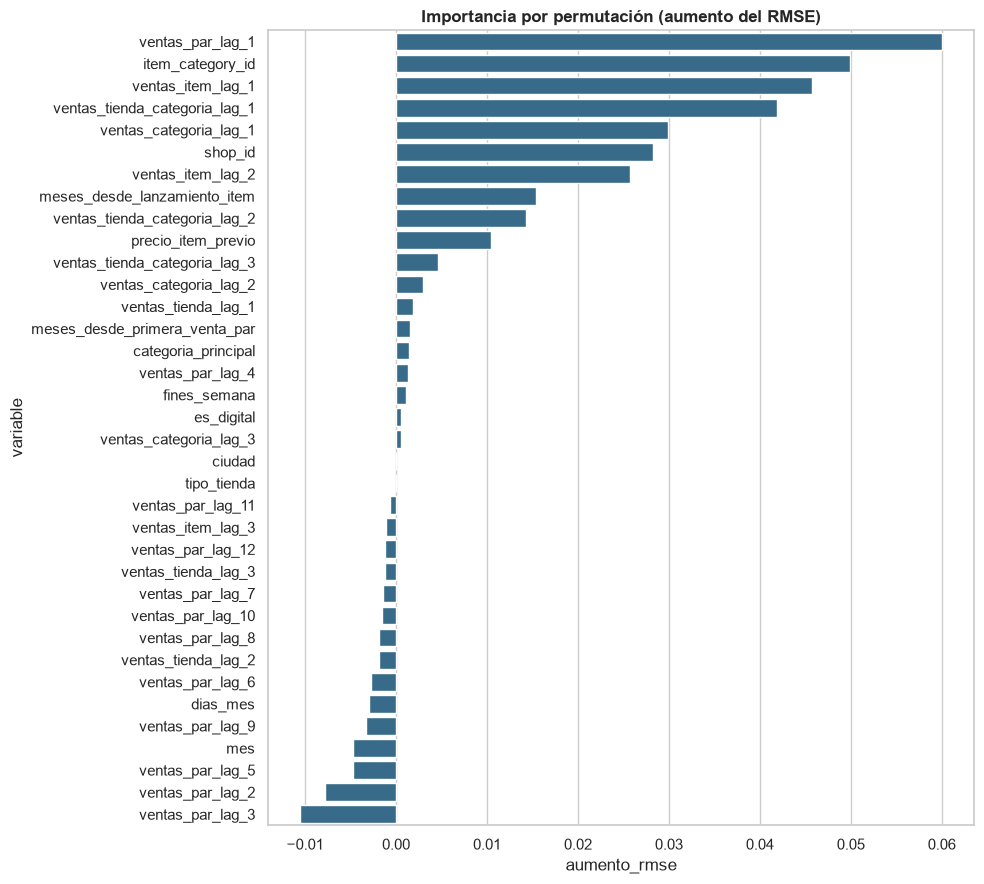

,variable,aumento_rmse,desv
0,ventas_par_lag_1,0.060,0.001
32,item_category_id,0.050,0.002
12,ventas_item_lag_1,0.046,0.001
21,ventas_tienda_categoria_lag_1,0.042,0.001
18,ventas_categoria_lag_1,0.030,0.002
31,shop_id,0.028,0.000
13,ventas_item_lag_2,0.026,0.001
25,meses_desde_lanzamiento_item,0.015,0.000
22,ventas_tienda_categoria_lag_2,0.014,0.001
24,precio_item_previo,0.010,0.001


In [9]:
CATEGORICAS = ["shop_id", "item_category_id", "ciudad", "tipo_tienda",
               "categoria_principal"]
CANDIDATAS = columnas_lag + NUMERICAS_CANDIDATAS + CATEGORICAS
X_prueba_modelo = base_ent[CANDIDATAS].copy()
for col in ["ciudad", "tipo_tienda", "categoria_principal"]:
    X_prueba_modelo[col] = X_prueba_modelo[col].astype("category").cat.codes
ajuste = base_ent["date_block_num"] <= 24
muestra = ajuste[ajuste].sample(1_000_000, random_state=SEMILLA).index
evaluacion = base_ent.index[base_ent["date_block_num"] >= 25]

inicio = time.time()
modelo_ref = HistGradientBoostingRegressor(
    max_iter=200, learning_rate=0.1, max_leaf_nodes=63,
    categorical_features=[CANDIDATAS.index(c) for c in CATEGORICAS],
    random_state=SEMILLA,
).fit(X_prueba_modelo.loc[muestra], base_ent.loc[muestra, "item_cnt_month"])
y_eval = base_ent.loc[evaluacion, "item_cnt_month"]
pred_eval = ds.recortar_target(
    modelo_ref.predict(X_prueba_modelo.loc[evaluacion]))
rmse_ref = root_mean_squared_error(y_eval, pred_eval)
rmse_ingenuo = root_mean_squared_error(
    y_eval, base_ent.loc[evaluacion, "ventas_par_lag_1"].clip(0, 20))
print(f"RMSE meses 25-26 | modelo de referencia: {rmse_ref:.4f} | "
      f"ingenuo (lag 1): {rmse_ingenuo:.4f} | "
      f"({time.time() - inicio:.0f} s)")

submuestra = evaluacion[::4]
importancia = permutation_importance(
    modelo_ref, X_prueba_modelo.loc[submuestra],
    base_ent.loc[submuestra, "item_cnt_month"],
    scoring="neg_root_mean_squared_error", n_repeats=3,
    random_state=SEMILLA, n_jobs=-1,
)
importancias = pd.DataFrame({
    "variable": CANDIDATAS,
    "aumento_rmse": importancia.importances_mean,
    "desv": importancia.importances_std,
}).sort_values("aumento_rmse", ascending=False)

fig, eje = plt.subplots(figsize=(10, 9))
sns.barplot(data=importancias, y="variable", x="aumento_rmse",
            color=COLOR, ax=eje)
eje.set_title("Importancia por permutación (aumento del RMSE)")
plt.tight_layout()
plt.show()
importancias

### 4.1 Lags y variables seleccionadas

El modelo de referencia obtiene un RMSE de **0.803** en los meses 25-26, contra **1.023** de la predicción ingenua (repetir el mes anterior): las variables candidatas sí aportan.

**Criterio de selección:** se conserva una variable si su importancia por permutación es positiva, o si tiene una justificación del EDA (estacionalidad) o de la consigna (variables exógenas de tienda y producto).

| Grupo | Se conservan | Se descartan y por qué |
|---|---|---|
| Lags del par | 1, 2, 3, 6, 12 | 4, 5, 7-11: redundantes con sus vecinos (importancia ≤ 0) |
| Lags del producto | 1, 2 | 3: importancia negativa |
| Lags de tienda-categoría | 1, 2 | 3: aporte mínimo (0.005) |
| Lags de categoría | 1 | 2 y 3: aporte ≤ 0.003 |
| Lags de tienda | 1 | 2 y 3: importancia negativa |
| Precio y antigüedad | `precio_item_previo`, `meses_desde_lanzamiento_item`, `meses_desde_primera_venta_par` | — |
| Calendario | `mes` (estacionalidad anual del EDA), `fines_semana` | `dias_mes`: no aporta y es redundante con `fines_semana` |
| Exógenas | `shop_id`, `item_category_id`, `ciudad`, `tipo_tienda`, `categoria_principal`, `es_digital` | `item_id`: 22 mil categorías; el producto entra por sus lags y su categoría |

En los lags del par hay importancias negativas porque, con lags correlacionados, desordenar uno no daña: el modelo usa el vecino. Se conservan el 2, el 3, el 6 y el 12 por la evidencia de la sección 2 y de la ACF/PACF. `ciudad` y `tipo_tienda` aportan poco porque la tienda ya las contiene; se conservan como ejemplo de exógenas derivadas del nombre de la tienda, como sugiere la consigna, y porque ayudan si llega una tienda nueva.

In [10]:
LAGS_PAR = [1, 2, 3, 6, 12]
LAGS_ITEM = [1, 2]
LAGS_TIENDA = [1]
LAGS_CATEGORIA = [1]
LAGS_TIENDA_CATEGORIA = [1, 2]

seleccion_lags = (
    [f"ventas_par_lag_{k}" for k in LAGS_PAR]
    + [f"ventas_item_lag_{k}" for k in LAGS_ITEM]
    + [f"ventas_tienda_lag_{k}" for k in LAGS_TIENDA]
    + [f"ventas_categoria_lag_{k}" for k in LAGS_CATEGORIA]
    + [f"ventas_tienda_categoria_lag_{k}" for k in LAGS_TIENDA_CATEGORIA]
)
OTRAS_NUMERICAS = ["precio_item_previo", "meses_desde_lanzamiento_item",
                   "meses_desde_primera_venta_par", "es_digital", "mes",
                   "fines_semana"]
SELECCION = seleccion_lags + OTRAS_NUMERICAS + CATEGORICAS
print(f"Variables seleccionadas: {len(SELECCION)}")

# Muestra de entrenamiento para probar cada proceso por separado.
muestra_fe = base_ent.sample(300_000, random_state=SEMILLA)
X_fe = muestra_fe[SELECCION].copy()
y_fe = muestra_fe["item_cnt_month"]
X_fe.dtypes.value_counts()

Variables seleccionadas: 22


float32    12
int64       4
str         3
float64     2
int16       1
Name: count, dtype: int64

## 5. Procesos de ingeniería de características

Cada proceso se prueba **por separado** sobre la muestra de 300 mil filas de entrenamiento, con transformadores de `feature-engine` y `scikit-learn`, para ver su efecto y justificar la elección. En el notebook 03 se encadenan en un solo `Pipeline`.

### 5.1 Imputación de variables numéricas

Los faltantes numéricos **no son errores**: tienen un significado.

- `meses_desde_lanzamiento_item` y `meses_desde_primera_venta_par` faltan cuando el producto (o el par) nunca se había vendido antes del mes. Se imputan con **0** (`ArbitraryNumberImputer`), un valor que no se usa (el mínimo real es 1), y antes se agrega una **bandera** de faltante (`AddMissingIndicator`): "producto nuevo" y "par nuevo".
- `precio_item_previo` falta para los productos nuevos. Se imputa con la **mediana** (`MeanMedianImputer`): es robusta al sesgo del precio, y la bandera de producto nuevo ya marca esas filas.
- Los **lags** no tienen faltantes en entrenamiento, pero sí los tendrían si se predijera más allá del último mes del historial. Por seguridad también reciben el imputador de mediana, igual que `es_digital`, `mes` y `fines_semana` (quedarían vacías con un producto fuera del catálogo o un mes fuera del calendario).

In [11]:
faltantes = (X_fe.isna().mean() * 100).rename("% faltantes")
display(faltantes[faltantes > 0].to_frame())

IMPUTAR_CERO = ["meses_desde_lanzamiento_item",
                "meses_desde_primera_venta_par"]
IMPUTAR_MEDIANA = (["precio_item_previo"] + seleccion_lags
                   + ["es_digital", "mes", "fines_semana"])
pasos_imputacion_num = [
    ("indicador_faltantes", AddMissingIndicator(variables=IMPUTAR_CERO)),
    ("imputar_cero", ArbitraryNumberImputer(arbitrary_number=0,
                                            variables=IMPUTAR_CERO)),
    ("imputar_mediana", MeanMedianImputer(imputation_method="median",
                                          variables=IMPUTAR_MEDIANA)),
]
imputado = Pipeline(pasos_imputacion_num).fit_transform(X_fe, y_fe)
print("Faltantes numéricos después:",
      int(imputado[IMPUTAR_CERO + IMPUTAR_MEDIANA].isna().sum().sum()))
print("Banderas nuevas:",
      [c for c in imputado.columns if c.endswith("_na")])
print("Mediana usada para precio_item_previo:",
      Pipeline(pasos_imputacion_num).fit(X_fe)
      .named_steps["imputar_mediana"].imputer_dict_["precio_item_previo"])
display(imputado.groupby("meses_desde_lanzamiento_item_na")
        .apply(lambda g: y_fe.loc[g.index].mean(), include_groups=False)
        .rename("media_target").to_frame())

,% faltantes
precio_item_previo,4.897
meses_desde_lanzamiento_item,4.897
meses_desde_primera_venta_par,47.890


Faltantes numéricos después: 0
Banderas nuevas: ['meses_desde_lanzamiento_item_na', 'meses_desde_primera_venta_par_na']
Mediana usada para precio_item_previo: 299.0


,media_target
meses_desde_lanzamiento_item_na,
0,0.274
1,0.660


### 5.2 Imputación de variables categóricas

Las categóricas exógenas (`ciudad`, `tipo_tienda`, `categoria_principal`) no tienen faltantes en el dataset: salen de los catálogos. Pero en producción pueden aparecer: el `Mapper` del notebook 03 deja NaN cuando llega una tienda o un producto que no está en el catálogo. Para **forzar** el proceso, como pide la consigna, se borra al azar el 2 % de cada una en una copia de la muestra.

Se imputa con una etiqueta propia, `"Desconocido"` (`CategoricalImputer(imputation_method="missing")`), y no con la moda: asignarle "Moscú" a una tienda desconocida sería inventar información.

`item_category_id` es un código categórico numérico: si llega un producto fuera del catálogo, queda vacío. Se imputa con el código **-1** (`ArbitraryNumberImputer`), que el codificador por media trata como una categoría nueva (le asigna la media global).

In [12]:
CATEGORICAS_TEXTO = ["ciudad", "tipo_tienda", "categoria_principal"]
CODIGOS_CATEGORICOS = ["item_category_id"]
rng = np.random.default_rng(SEMILLA)
X_forzado = X_fe.copy()
for col in CATEGORICAS_TEXTO + CODIGOS_CATEGORICOS:
    borrar = rng.random(len(X_forzado)) < 0.02
    X_forzado.loc[borrar, col] = np.nan
print("Faltantes forzados:",
      X_forzado[CATEGORICAS_TEXTO + CODIGOS_CATEGORICOS].isna().sum()
      .to_dict())

pasos_imputacion_cat = [
    ("imputar_categoricas", CategoricalImputer(
        imputation_method="missing", fill_value="Desconocido",
        variables=CATEGORICAS_TEXTO)),
    ("imputar_codigos", ArbitraryNumberImputer(
        arbitrary_number=-1, variables=CODIGOS_CATEGORICOS)),
]
imputado_cat = Pipeline(pasos_imputacion_cat).fit_transform(X_forzado)
print("Faltantes después:",
      imputado_cat[CATEGORICAS_TEXTO + CODIGOS_CATEGORICOS].isna().sum()
      .to_dict())
imputado_cat["tipo_tienda"].value_counts().to_frame()

Faltantes forzados: {'ciudad': 5914, 'tipo_tienda': 5977, 'categoria_principal': 6013, 'item_category_id': 6086}
Faltantes después: {'ciudad': 0, 'tipo_tienda': 0, 'categoria_principal': 0, 'item_category_id': 0}


,count
tipo_tienda,
Centro comercial,176146
Centro comercial y de ocio,80687
Tienda de calle,24548
En línea,11845
Desconocido,5977
Itinerante,421
Liquidación,376


### 5.3 Codificación de variables categóricas

La consigna pide tratar la tienda y el producto como **variables exógenas**. La codificación depende de la cardinalidad y de la relación con el target (razón de correlación η):

- **Alta cardinalidad** (`shop_id`, `item_category_id`, `ciudad`): one-hot agregaría más de 150 columnas casi vacías. Se usa **codificación por la media del target** (`MeanEncoder`, con suavizado automático y `unseen="encode"`, que asigna la media global a categorías nuevas). Se ajusta solo con entrenamiento, dentro del pipeline, para no filtrar el target de validación.
- **Baja cardinalidad** (`tipo_tienda`, `categoria_principal`): `RareLabelEncoder` agrupa las categorías con menos del 1 % de las filas en "Rare", y después `OneHotEncoder` crea una columna binaria por categoría.
- `item_id` **no se codifica**: con 22 mil productos, la información del producto entra por sus lags, su precio, su antigüedad y su categoría.

In [13]:
def razon_correlacion(grupos: pd.Series, valores: pd.Series) -> float:
    """Razón de correlación η entre una categórica y el target."""
    medias = valores.groupby(grupos).transform("mean")
    total = ((valores - valores.mean()) ** 2).sum()
    return float(np.sqrt(((medias - valores.mean()) ** 2).sum() / total))


cardinalidad = pd.DataFrame({
    "categorias": X_fe[CATEGORICAS].nunique(),
    "eta": [razon_correlacion(X_fe[c], y_fe) for c in CATEGORICAS],
})
display(cardinalidad)

MEDIA_TARGET = ["shop_id", "item_category_id", "ciudad"]
ONE_HOT = ["tipo_tienda", "categoria_principal"]
pasos_codificacion = [
    ("agrupar_raras", RareLabelEncoder(tol=0.01, n_categories=4,
                                       variables=ONE_HOT)),
    ("one_hot", OneHotEncoder(variables=ONE_HOT)),
    ("media_target", MeanEncoder(variables=MEDIA_TARGET, smoothing="auto",
                                 unseen="encode", ignore_format=True)),
]
codificado = Pipeline(pasos_codificacion).fit_transform(X_fe, y_fe)
nuevas = [c for c in codificado.columns if c not in X_fe.columns]
print(f"Columnas one-hot nuevas ({len(nuevas)}):", nuevas)
display(codificado[MEDIA_TARGET].describe().T)

,categorias,eta
shop_id,53,0.179
item_category_id,74,0.326
ciudad,30,0.125
tipo_tienda,6,0.026
categoria_principal,14,0.177


Columnas one-hot nuevas (13): ['tipo_tienda_Centro comercial y de ocio', 'tipo_tienda_Centro comercial', 'tipo_tienda_Tienda de calle', 'tipo_tienda_En línea', 'tipo_tienda_Rare', 'categoria_principal_Regalos', 'categoria_principal_Música', 'categoria_principal_Cine', 'categoria_principal_Juegos', 'categoria_principal_Rare', 'categoria_principal_Programas', 'categoria_principal_Accesorios', 'categoria_principal_Libros']


,count,mean,std,min,25%,50%,75%,max
shop_id,"300,000.000",0.293,0.215,0.055,0.181,0.229,0.301,1.171
item_category_id,"300,000.000",0.290,0.333,0.000,0.162,0.228,0.249,9.092
ciudad,"300,000.000",0.293,0.151,0.085,0.181,0.226,0.490,0.760


### 5.4 Tratamiento de outliers

En el EDA se vieron cantidades extremas (hasta 1,644 unidades de un par en un mes) y precios atípicos.

- **Todos los lags:** las devoluciones dejan meses con ventas netas **negativas** (hasta -22 en un par). Como el target tiene piso 0, todos los lags se recortan por abajo en 0.
- **Lags del par:** como el target se recorta a 20, sus lags se recortan al mismo tope con `ArbitraryOutlierCapper` (rango [0, 20]). Así el modelo ve la misma escala en la entrada y en la salida.
- **Lags agregados y precio:** tienen colas largas (por ejemplo, la bolsa 20949 vende miles de unidades). Se recortan con `Winsorizer` por **cuantiles** en la cola derecha (percentil 99.5), que no elimina filas.

In [14]:
LAGS_AGREGADOS = [c for c in seleccion_lags
                  if not c.startswith("ventas_par_")]
WINSORIZAR = LAGS_AGREGADOS + ["precio_item_previo"]
X_out = Pipeline(pasos_imputacion_num).fit_transform(X_fe)
resumen_out = X_out[[f"ventas_par_lag_{k}" for k in LAGS_PAR]
                    + WINSORIZAR].describe(
    percentiles=[0.5, 0.99, 0.995]).T[["min", "50%", "99%", "99.5%",
                                       "max"]]
print("Filas con algún lag negativo:",
      int((X_out[seleccion_lags] < 0).any(axis=1).sum()))

pasos_outliers = [
    ("recortar_lags", ArbitraryOutlierCapper(
        max_capping_dict={f"ventas_par_lag_{k}": 20 for k in LAGS_PAR},
        min_capping_dict={c: 0 for c in seleccion_lags})),
    ("winsorizar", Winsorizer(capping_method="quantiles", tail="right",
                              fold=0.005, variables=WINSORIZAR)),
]
recortado = Pipeline(pasos_outliers).fit_transform(X_out)
resumen_out["max_despues"] = recortado[resumen_out.index].max()
resumen_out["pct_recortado"] = (
    (X_out[resumen_out.index] > resumen_out["max_despues"]).mean() * 100)
resumen_out

Filas con algún lag negativo: 213


,min,50%,99%,99.5%,max,max_despues,pct_recortado
ventas_par_lag_1,-1.000,0.000,5.000,8.000,"1,074.000",20.000,0.100
ventas_par_lag_2,-1.000,0.000,5.000,8.000,795.000,20.000,0.117
ventas_par_lag_3,-1.000,0.000,5.000,9.000,764.000,20.000,0.118
ventas_par_lag_6,-2.000,0.000,5.000,8.000,759.000,20.000,0.111
ventas_par_lag_12,-2.000,0.000,5.000,8.000,978.000,20.000,0.093
ventas_item_lag_1,-18.000,4.000,197.000,296.000,"12,557.000",296.000,0.500
ventas_item_lag_2,-22.000,4.000,206.000,312.000,"12,557.000",312.000,0.499
ventas_tienda_lag_1,0.000,"1,738.000","9,865.000","12,102.000","16,318.000","12,102.000",0.427
ventas_categoria_lag_1,0.000,"5,647.000","28,598.000","28,598.000","28,598.000","28,598.000",0.000
ventas_tienda_categoria_lag_1,-1.000,66.000,"1,318.000","1,689.000","4,824.000","1,689.000",0.490


### 5.5 Transformación de variables numéricas

Después del recorte, las variables de conteo y el precio siguen muy sesgadas a la derecha (muchos ceros y pocos valores altos). Como son conteos no negativos con ceros, se usa **log(1 + x)** (`LogCpTransformer` con `C=1`), que es fácil de interpretar y revertir.

**Criterio:** se transforma una variable continua si su |sesgo| > 0.75 **y** el logaritmo reduce el |sesgo|. En las variables agregadas por tienda, el log puede pasarse al otro lado y dejar un sesgo izquierdo mayor; en ese caso no se transforma. Las variables de calendario y las banderas no se transforman.

,sesgo_antes,sesgo_con_log,se_transforma,sesgo_despues
ventas_par_lag_1,9.179,3.394,True,3.394
ventas_par_lag_2,9.147,3.450,True,3.450
ventas_par_lag_3,9.202,3.501,True,3.501
ventas_par_lag_6,9.646,3.661,True,3.661
ventas_par_lag_12,10.086,4.086,True,4.086
ventas_item_lag_1,5.334,0.560,True,0.560
ventas_item_lag_2,5.483,0.569,True,0.569
ventas_tienda_lag_1,2.307,-3.953,False,2.307
ventas_categoria_lag_1,0.932,-0.833,True,-0.833
ventas_tienda_categoria_lag_1,3.561,-0.487,True,-0.487


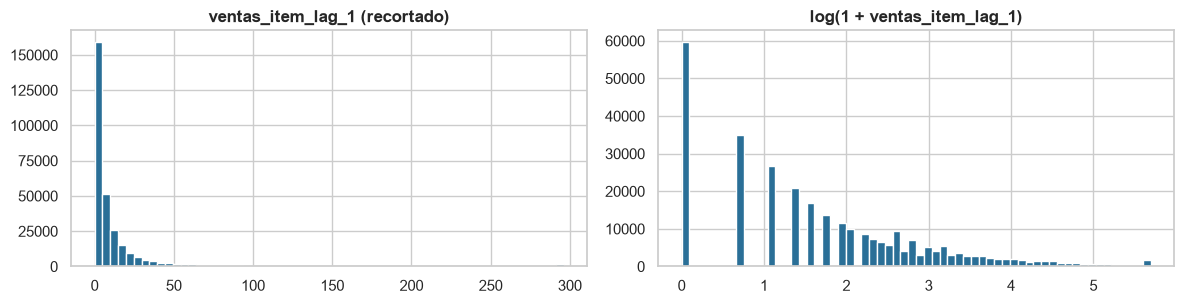

In [15]:
X_tr = Pipeline(pasos_outliers).fit_transform(X_out)
CONTINUAS = seleccion_lags + ["precio_item_previo",
                              "meses_desde_lanzamiento_item",
                              "meses_desde_primera_venta_par"]
sesgo = X_tr[CONTINUAS].skew().rename("sesgo_antes").to_frame()
sesgo["sesgo_con_log"] = np.log1p(X_tr[CONTINUAS]).skew()
sesgo["se_transforma"] = ((sesgo["sesgo_antes"].abs() > 0.75)
                          & (sesgo["sesgo_con_log"].abs()
                             < sesgo["sesgo_antes"].abs()))
TRANSFORMAR_LOG = sesgo.index[sesgo["se_transforma"]].tolist()
pasos_transformacion = [
    ("log1p", LogCpTransformer(variables=TRANSFORMAR_LOG, C=1)),
]
transformado = Pipeline(pasos_transformacion).fit_transform(X_tr)
sesgo["sesgo_despues"] = transformado[CONTINUAS].skew()
display(sesgo)

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.2))
ejes[0].hist(X_tr["ventas_item_lag_1"], bins=60, color=COLOR)
ejes[0].set_title("ventas_item_lag_1 (recortado)")
ejes[1].hist(transformado["ventas_item_lag_1"], bins=60, color=COLOR)
ejes[1].set_title("log(1 + ventas_item_lag_1)")
plt.tight_layout()
plt.show()

### 5.6 Escalado de características

Ridge y la red neuronal (MLP) son sensibles a la escala de las variables; los árboles no. Para que todos los modelos del torneo reciban la misma entrada, se aplica `StandardScaler` (media 0 y desviación 1) a **todas** las columnas finales, envuelto en `SklearnTransformerWrapper` para conservar los nombres de las columnas. Antes se eliminan los identificadores que no son features (`date_block_num`, `item_id`).

In [16]:
pasos_previos = (pasos_imputacion_num + pasos_imputacion_cat
                 + pasos_codificacion + pasos_outliers
                 + pasos_transformacion)
X_previo = Pipeline(pasos_previos).fit_transform(X_fe, y_fe)
pasos_escalado = [
    ("escalar", SklearnTransformerWrapper(StandardScaler())),
]
escalado = Pipeline(pasos_escalado).fit_transform(X_previo)
display(escalado.agg(["mean", "std"]).T.head(12))
print(f"Columnas finales: {escalado.shape[1]} | faltantes: "
      f"{int(escalado.isna().sum().sum())}")

,mean,std
ventas_par_lag_1,0.000,1.000
ventas_par_lag_2,0.000,1.000
ventas_par_lag_3,-0.000,1.000
ventas_par_lag_6,-0.000,1.000
ventas_par_lag_12,-0.000,1.000
ventas_item_lag_1,0.000,1.000
ventas_item_lag_2,0.000,1.000
ventas_tienda_lag_1,0.000,1.000
ventas_categoria_lag_1,-0.000,1.000
ventas_tienda_categoria_lag_1,-0.000,1.000


Columnas finales: 35 | faltantes: 0


## 6. Resumen: variables, transformaciones y mapeos

Este es el proceso que el notebook 03 implementa como un `Pipeline` de sklearn. La entrada del pipeline son filas `(date_block_num, shop_id, item_id)`, como las de test con `date_block_num = 34`.

**1. Mapeos (`Mapper`)**: agregan las variables exógenas a partir de los catálogos traducidos y del calendario. Un valor que no esté en el diccionario queda como NaN y lo trata la imputación.

| Columna nueva | Origen | Diccionario |
|---|---|---|
| `item_category_id` | `item_id` | `items.csv` |
| `categoria_principal`, `es_digital` | `item_category_id` | `item_categories_traducido.csv` |
| `ciudad`, `tipo_tienda` | `shop_id` | `shops_traducido.csv` |
| `mes`, `fines_semana` (y `dias_mes`, que se elimina) | `date_block_num` | calendario (`ds.calendario`) |

**2. Lags (`GeneradorLags`)**: con el historial mensual de ventas, y **solo con meses anteriores** al de la fila (para el mes 34 se usan el 33, el 32, …, el 22):

- par tienda-producto: lags 1, 2, 3, 6 y 12;
- producto en todas las tiendas: lags 1 y 2;
- tienda: lag 1; categoría: lag 1; tienda-categoría: lags 1 y 2;
- `precio_item_previo`, `meses_desde_lanzamiento_item` y `meses_desde_primera_venta_par`.

**3. Imputación**

| Proceso | Variables | Operación |
|---|---|---|
| Numérica con bandera | `meses_desde_lanzamiento_item`, `meses_desde_primera_venta_par` | `AddMissingIndicator` (banderas `_na`: producto nuevo y par nuevo) + `ArbitraryNumberImputer(0)` |
| Numérica | `precio_item_previo`, todos los lags, `es_digital`, `mes`, `fines_semana` | `MeanMedianImputer("median")` |
| Categórica | `ciudad`, `tipo_tienda`, `categoria_principal` | `CategoricalImputer(fill_value="Desconocido")` |
| Código categórico | `item_category_id` | `ArbitraryNumberImputer(-1)` (categoría nueva para el codificador) |

`meses_desde_primera_venta_par` tiene un 48 % de faltantes. La skill sugiere descartar variables con más de 20 % de faltantes, pero aquí el faltante **tiene significado** (el par nunca había vendido), así que se conserva con su bandera.

**4. Codificación**

| Variables | Operación |
|---|---|
| `tipo_tienda`, `categoria_principal` | `RareLabelEncoder(tol=0.01)` + `OneHotEncoder` (13 columnas binarias) |
| `shop_id`, `item_category_id`, `ciudad` | `MeanEncoder(smoothing="auto", unseen="encode")`: media del target, ajustada solo con entrenamiento |

**5. Outliers**

| Variables | Operación |
|---|---|
| Todos los lags | piso 0 (las devoluciones dejan ventas netas negativas) |
| Lags del par | tope 20, igual que el target (`ArbitraryOutlierCapper`) |
| Lags agregados y `precio_item_previo` | `Winsorizer` por cuantiles, cola derecha al percentil 99.5 |

**6. Transformación**: `LogCpTransformer(C=1)`, es decir log(1 + x), en las continuas con |sesgo| > 0.75 en las que el log reduce el sesgo: lags del par, del producto, de categoría y de tienda-categoría, `precio_item_previo` y `meses_desde_primera_venta_par`. No se transforma `ventas_tienda_lag_1` (el log empeora su sesgo: de 2.3 a -4.0) ni `meses_desde_lanzamiento_item` (es simétrica).

**7. Eliminación y escalado**: se eliminan `date_block_num`, `item_id` y `dias_mes`, y se aplica `StandardScaler` a todas las columnas restantes (envuelto en `SklearnTransformerWrapper`).

**Resultado:** 35 columnas numéricas sin faltantes. La configuración se guarda en `pipeline_config.yaml`, que leen los notebooks 03, 04 y 05.

In [17]:
config = {
    "TARGET": "item_cnt_month",
    "RANGO_TARGET": {"min": 0, "max": 20},
    "MESES_ENTRENAMIENTO": [MESES_ENTRENAMIENTO.start,
                            MESES_ENTRENAMIENTO.stop - 1],
    "MESES_VALIDACION": [MESES_VALIDACION.start, MESES_VALIDACION.stop - 1],
    "LAGS": {"par": LAGS_PAR, "item": LAGS_ITEM, "tienda": LAGS_TIENDA,
             "categoria": LAGS_CATEGORIA,
             "tienda_categoria": LAGS_TIENDA_CATEGORIA},
    "IMPUTAR_CERO": IMPUTAR_CERO,
    "IMPUTAR_MEDIANA": IMPUTAR_MEDIANA,
    "IMPUTAR_CATEGORICAS": CATEGORICAS_TEXTO,
    "IMPUTAR_CODIGOS": CODIGOS_CATEGORICOS,
    "CODIFICAR_MEDIA_TARGET": MEDIA_TARGET,
    "CODIFICAR_ONE_HOT": ONE_HOT,
    "RECORTAR_LAGS_PAR": [f"ventas_par_lag_{k}" for k in LAGS_PAR],
    "WINSORIZAR": WINSORIZAR,
    "TRANSFORMAR_LOG": TRANSFORMAR_LOG,
    "ELIMINAR": ["date_block_num", "item_id", "dias_mes"],
}
pd.Series({k: v for k, v in config.items()}).to_frame("valor")

,valor
TARGET,item_cnt_month
RANGO_TARGET,"{'min': 0, 'max': 20}"
MESES_ENTRENAMIENTO,"[12, 26]"
MESES_VALIDACION,"[27, 33]"
LAGS,"{'par': [1, 2, 3, 6, 12], 'item': [1, 2], 'tie..."
IMPUTAR_CERO,"[meses_desde_lanzamiento_item, meses_desde_pri..."
IMPUTAR_MEDIANA,"[precio_item_previo, ventas_par_lag_1, ventas_..."
IMPUTAR_CATEGORICAS,"[ciudad, tipo_tienda, categoria_principal]"
IMPUTAR_CODIGOS,[item_category_id]
CODIFICAR_MEDIA_TARGET,"[shop_id, item_category_id, ciudad]"


In [18]:
import yaml

from future_sales.config import PROJ_ROOT

encabezado = (
    "# Configuración del pipeline de Predict Future Sales.\n"
    "# Generada por notebooks/02_feature_exploration.ipynb (sección 6).\n"
    "# La leen los notebooks 03 (pipeline), 04 (entrenamiento) y 05.\n"
)
with open(PROJ_ROOT / "pipeline_config.yaml", "w", encoding="utf-8") as f:
    f.write(encabezado)
    yaml.safe_dump(config, f, allow_unicode=True, sort_keys=False)
print((PROJ_ROOT / "pipeline_config.yaml").read_text(encoding="utf-8"))

# Configuración del pipeline de Predict Future Sales.
# Generada por notebooks/02_feature_exploration.ipynb (sección 6).
# La leen los notebooks 03 (pipeline), 04 (entrenamiento) y 05.
TARGET: item_cnt_month
RANGO_TARGET:
  min: 0
  max: 20
MESES_ENTRENAMIENTO:
- 12
- 26
MESES_VALIDACION:
- 27
- 33
LAGS:
  par:
  - 1
  - 2
  - 3
  - 6
  - 12
  item:
  - 1
  - 2
  tienda:
  - 1
  categoria:
  - 1
  tienda_categoria:
  - 1
  - 2
IMPUTAR_CERO:
- meses_desde_lanzamiento_item
- meses_desde_primera_venta_par
IMPUTAR_MEDIANA:
- precio_item_previo
- ventas_par_lag_1
- ventas_par_lag_2
- ventas_par_lag_3
- ventas_par_lag_6
- ventas_par_lag_12
- ventas_item_lag_1
- ventas_item_lag_2
- ventas_tienda_lag_1
- ventas_categoria_lag_1
- ventas_tienda_categoria_lag_1
- ventas_tienda_categoria_lag_2
- es_digital
- mes
- fines_semana
IMPUTAR_CATEGORICAS:
- ciudad
- tipo_tienda
- categoria_principal
IMPUTAR_CODIGOS:
- item_category_id
CODIFICAR_MEDIA_TARGET:
- shop_id
- item_category_id
- ciudad
CODIFICAR